In [77]:
import cv2
from cycler import cycler
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
from scipy import stats
from skimage.metrics import (peak_signal_noise_ratio as psnr,
                             structural_similarity as ssim)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

plt.rcParams["axes.prop_cycle"] = cycler(color=plt.cm.Set2.colors)
plt.rcParams["image.cmap"] = "plasma"

o3161 = cv2.imread(f'data/images_original/3.16.1. original.jpg',
                   cv2.IMREAD_GRAYSCALE)
roi_df = pd.read_csv("roi_labels.csv")

data_path = "data/images_original"
processed = "processed"

## Accessing an ROI

In [54]:
# ROI
roi_df = pd.read_csv("roi_labels.csv")

def get_roi(row, path, h = 1024//4, w = 1024//4):
    file_name = row.roi.split("-")[0]
    image = cv2.imread(f"{path}/{file_name}.png", cv2.IMREAD_GRAYSCALE)
    return image[row.y:row.y+h, row.x:row.x+w]

## Image Pyramid and Applications

Image pyramids are hierarchical representations of an image, a collection of decreasing resolution 25% smaller than previous one arranged in the shape of a pyramid.

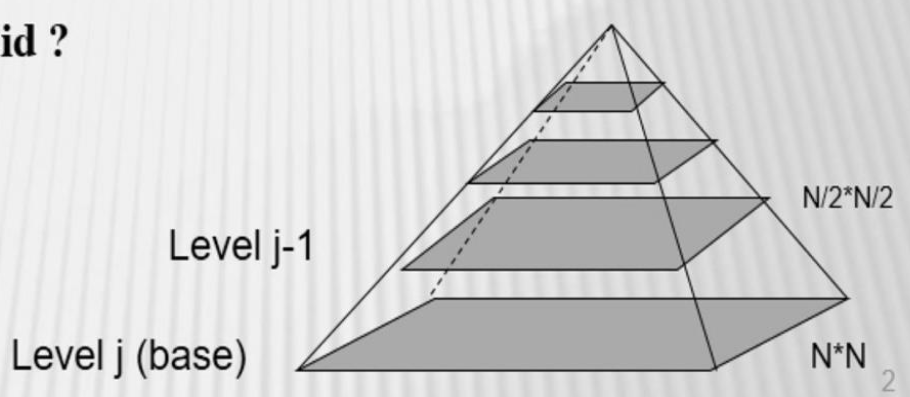

Computationally efficient as the downsampled images require less memory and processing power than the original and preserves important image features because gaussian filter smooths high-frequency components. Some image pyramids are overcomplete (containing redundant information), such as Gaussian pyramids where the total number of samples is about 4/3 x N.

A *convolutional neural network (CNN)* consists of a series of layers concatenated in a feedforward manner, where each layer has a convolutional sublayer (CL) and pooling sublayer (PL).

### Advantages
- Efficently capture features for analysis for various scales, such as edges and textures
- Reduce redundancy for efficient data representation

### Examples in Image Modeling
- efficient coding and compression
- image enhancement and restoration
- detailed image analysis and synthesis

### Examples

Gaussian, Laplacian, Wavelet/QMF

### Applications
1. scale-invariant pattern matching and detection (search across scales)
2. image blending by blending multi-resolution representations
3. motion analysis
4. image compression - represent images efficiently by separating course structures from fine details
5. progressive image transmission - send low-resolution levels first for fast preview then refine the image as higher-resolution data arrives
6. multi-resolution editing and texture synthesis - modify image attributes or generate realistic textures smoothly across different spatial frequencies
7. computational efficieny - speed up computer vision algorithms by running initial processing on smaller, lower-resolution levels

### Matching

- in template matching used in classification, a smaller (template) image is compared to all subregions of a source image by computing numerical index to assess match quality (sum of absolute differences or sum of squared differences).
- correlation measures the degree to which 2 variables agree, not necessarily actual value but behavior
- grey-level correlation formula:$$corr = \frac{\sum^{N-1}_{i=0}{(x_i - \bar{x}) \cdot (y_i - \bar{y})}/\sqrt{\sum^{N-1}_{i=0}{(x_i - \bar{x})^2} \cdot \sum^{N-1}_{i=0}(y_i - \bar{y})^2}$$ where x = template gray level image, $\bar{x}$ = average template gray level image, y = source image level, N the number of pixels in the section image (template image size = columns * rows) and the value cor is between -1 and + 1 with 1 being stronger.

## Feature extraction from feature pyramids (FPNs)

- scale invariance
- top-down pathway
- lateral connections
- improved accuracy

## Gaussian Pyramid Algorithm

```
# g0 = image, n = 0
# gn' = blur(gn)
# gn+1 = downsample(gn')
# n = n+1
# repeat until shape is 1x1
```

## Laplacian Pyramid

$$\delta^2f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$$

```
# g0 = image, n = 0
# gn = gaussian(gn)
# gn+1 = downsample(gn)
# gn_p = expand(gn+1)
# Ln = gn - gn_p
# n = n+1
```

You can also make the Gaussian pyramid first then make $L_i = G_i - expand(G_{i+1})$ where expand upsamples and interpolates.

## Shannon Entropy

Measures the average uncertainty (or information content) in a random variable's outcome. For an image, you can use the histogram bin counts over the total counts as the probability then you can use the following to find the entropy: $$H(X) = \sum{p_ilog(p_i)}$$. H(X) is highest when all outcomes are equally likely.

## Blending

$$I = m*I^A + (1-m)*I^B$$

Build Gaussian pyramids of $I^A$ and $I^B$ then create their Laplacian pyramids. Blend the pyramids and reconstruct the final image.

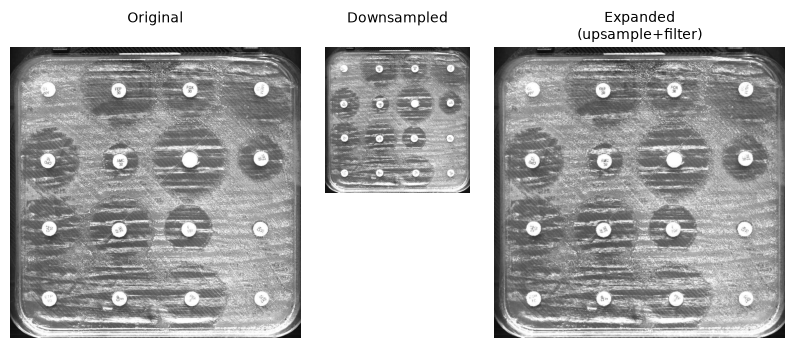

In [15]:
## Downsampling and Upsampling

def downsample(image):
    """Drop odd rows and columns"""
    return image[::2,  ::2]

def upsample(image):
    height, width = image.shape[:2]
    upsampled = np.zeros((height*2, width*2)) 
    upsampled[::2, ::2] = image
    return upsampled

def expand(image, func=None, **kwargs):
    """Add rows and columns"""
    upsampled = upsample(image)
    if func is None:
        kernel = np.array([[0.25, 0.5, 0.25],
                           [0.5, 1, 0.5],
                           [0.25, 0.5, 0.25]])
        upsampled = cv2.filter2D(upsampled, -1, kernel=kernel)
    else:
        upsampled = func(upsampled, **kwargs)
    return upsampled

downsampled = downsample(o3161)
expanded = expand(downsampled)

titles = ["Original\n", "Downsampled\n", "Expanded\n(upsample+filter)"]
images = [o3161, downsampled, expanded]
widths = [im.shape[1] for im in images]

fig, axes = plt.subplots(1, 3, sharey=True, gridspec_kw={"width_ratios": widths, "wspace": 0.1},
                        figsize=(10, 6))
for i in range(len(images)):
    axes[i].set_title(titles[i], fontsize=10)
    axes[i].imshow(images[i], cmap="gray", vmin=0, vmax=255)
    axes[i].axis("off")

In [25]:
# Plotting written by Claude Sonnet 5.5
# The histogram and entropy lines are mine.
def show_pyramid(p, title, w=None, h=None, hist=False, cols=4):
    rows = math.ceil(len(p) / cols)
    fig = plt.figure(figsize=(w, h) if w is not None and h is not None else None)
    # With histograms, each row of images is followed by a row of histograms
    total_rows = rows * 2 if hist else rows
    # Make every grid cell square so the images touch, and center the grid
    fig_w, fig_h = fig.get_size_inches()
    side = min(0.98 * fig_w / cols, 0.92 * fig_h / total_rows)
    grid_w, grid_h = side * cols / fig_w, side * total_rows / fig_h
    left, top = (1 - grid_w) / 2, 0.93
    grid = fig.add_gridspec(total_rows, cols, wspace=0, hspace=0,
                            left=left, right=left + grid_w, top=top, bottom=top - grid_h)
    for i, level in enumerate(p):
        row, col = divmod(i, cols)
        ax = fig.add_subplot(grid[row * 2 if hist else row, col])
        ax.imshow(level, cmap="gray")
        ax.axis("off")
        if hist:
            cell = fig.add_subplot(grid[row * 2 + 1, col])
            cell.axis("off")
            ax_hist = cell.inset_axes([0.15, 0.2, 0.8, 0.6])
            counts, bin_edges = np.histogram(level.ravel(), bins=511, range=(-255, 256))
            ps = counts / counts.sum()
            # remove nonzero
            ps = ps[ps > 0]
            entropy = -sum(ps*np.log(ps))
            ax_hist.bar(bin_edges[:-1], counts, edgecolor="C0")
            ax_hist.tick_params(axis="both", labelsize=7)
            ax_hist.set_title(f"Level {i}, H(X) = {entropy:.2f}", fontsize=9)
    fig.suptitle(title, y=0.98)
    plt.show()

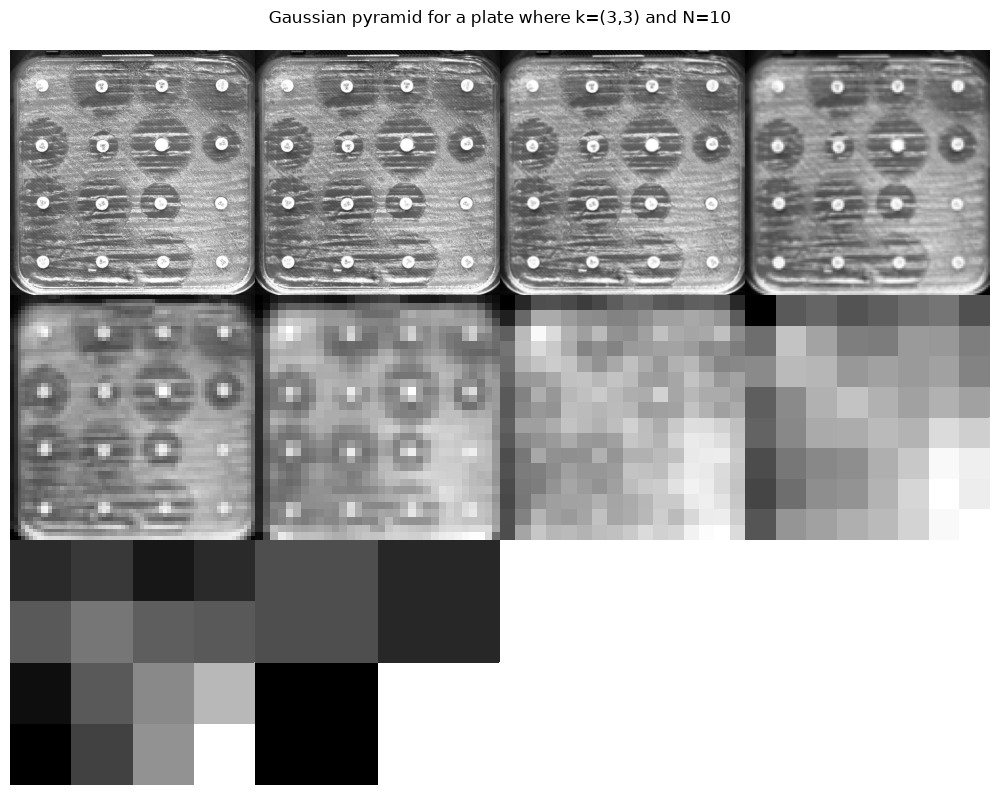

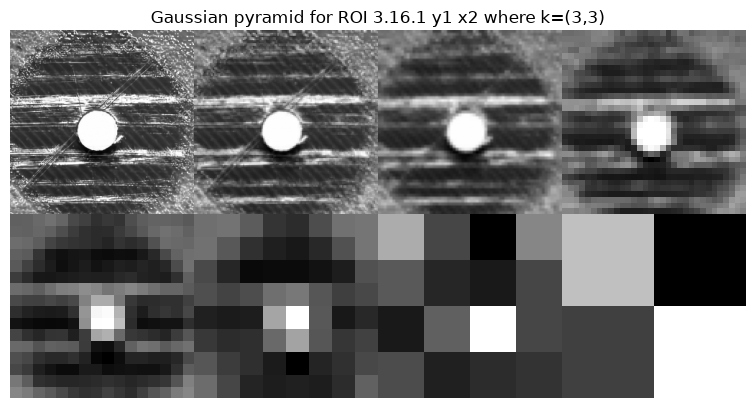

In [29]:
## Gaussian Pyramid

# g0 = image, n = 0
# gn' = blur(gn)
# gn+1 = downsample(gn')
# n = n+1
# repeat until shape is 1x1

def gaussian_pyramid(image, N=5, ksize=(3,3)):
    n = 0
    gs = [image]
    h, w = image.shape[:2]
    while h > 1 and w > 1 and n < N - 1:
        gn_p = cv2.blur(gs[n], ksize=ksize)
        h, w = gn_p.shape[:2]
        gs.append(downsample(gn_p))
        n += 1
    return gs

o3161_gp = gaussian_pyramid(o3161, N=10)
show_pyramid(o3161_gp, "Gaussian pyramid for a plate where k=(3,3) and N=10", 10, 8)

d3161y1x2_gp = gaussian_pyramid(d3161_y1_x2, N=8)
show_pyramid(d3161y1x2_gp, "Gaussian pyramid for ROI 3.16.1 y1 x2 where k=(3,3)", 8, 4)

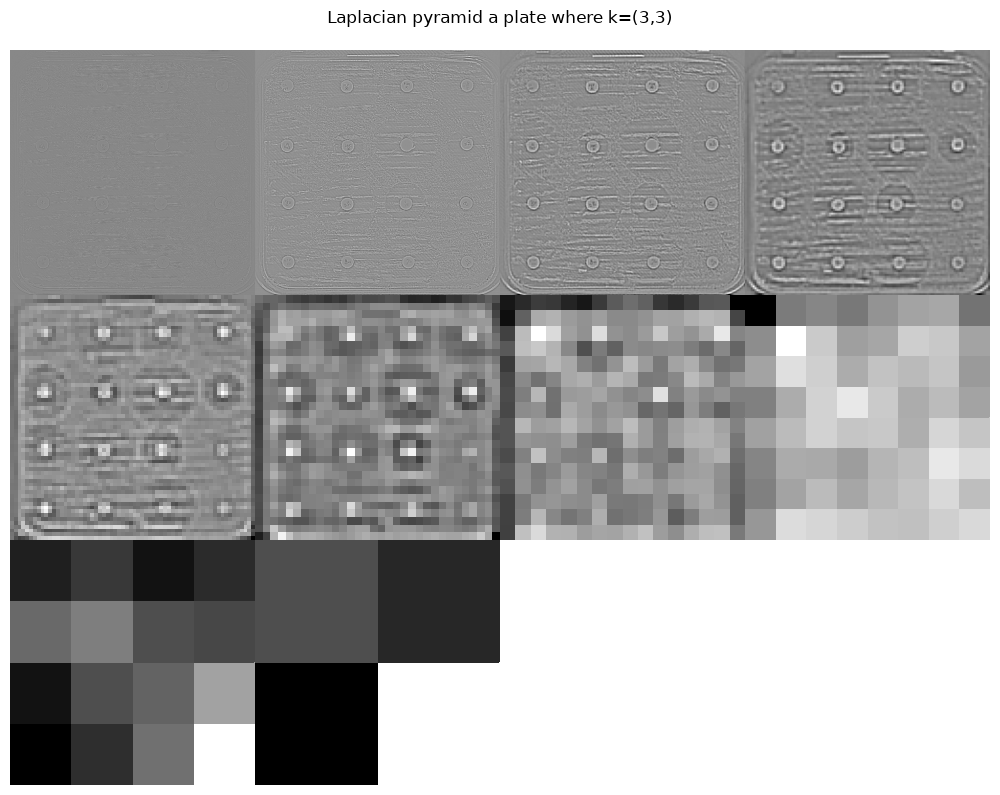

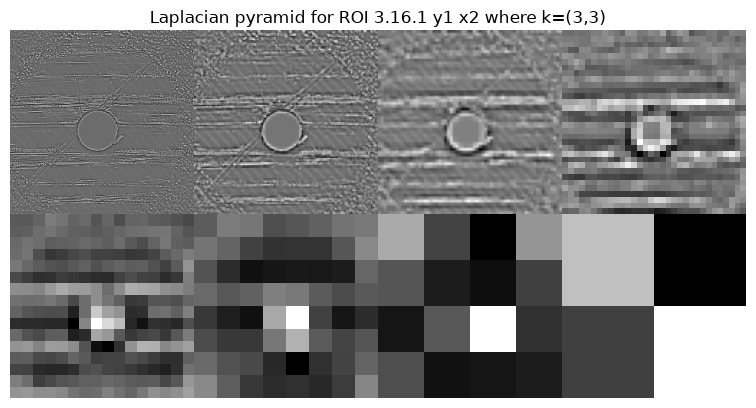

In [30]:
## Display Laplacian

# g0 = image, n = 0
# gn = gaussian(gn)
# gn+1 = downsample(gn)
# gn_p = expand(gn+1)
# Ln = gn - gn_p
# n = n+1

def laplacian_pyramid(gpyramid, ksize=(3,3)):
    Ls = []
    for n in range(len(gpyramid[:-1])):
        Ls.append(gpyramid[n].astype(float) - expand(gpyramid[n+1]).astype(float))
    Ls.append(gpyramid[-1].astype(float))
    return Ls

o3161_lp = laplacian_pyramid(o3161_gp, ksize=(3, 3))
show_pyramid(o3161_lp, "Laplacian pyramid a plate where k=(3,3)", 10, 8)

d3161y1x2_lp = laplacian_pyramid(d3161y1x2_gp)
show_pyramid(d3161y1x2_lp, "Laplacian pyramid for ROI 3.16.1 y1 x2 where k=(3,3)", 8, 4)

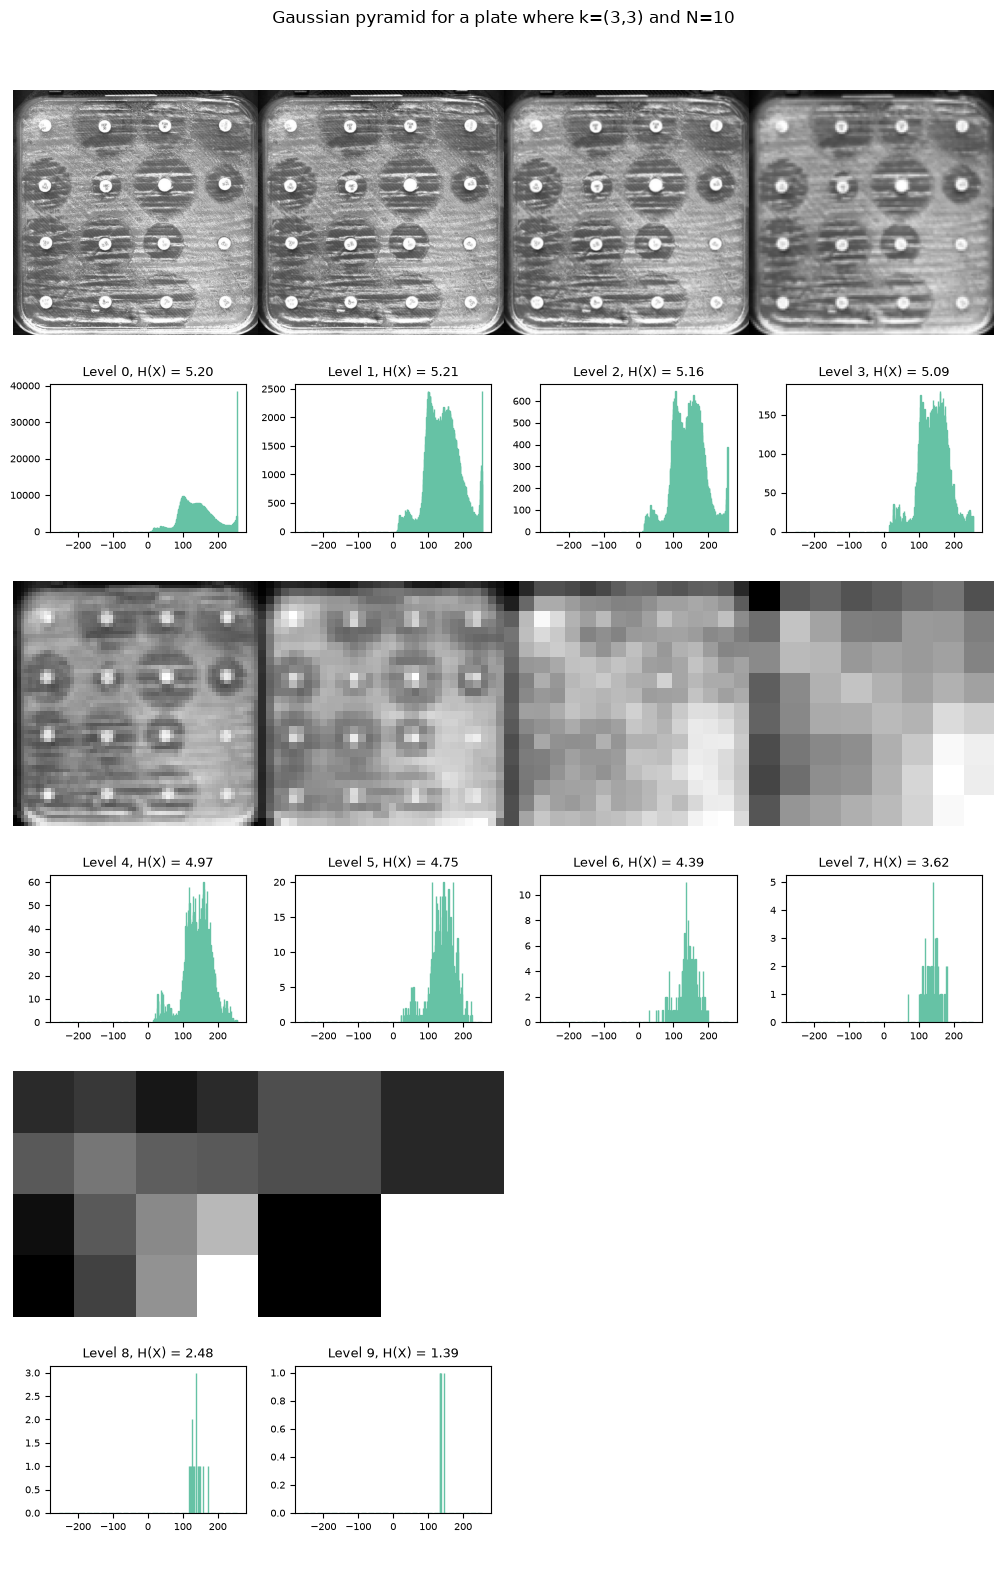

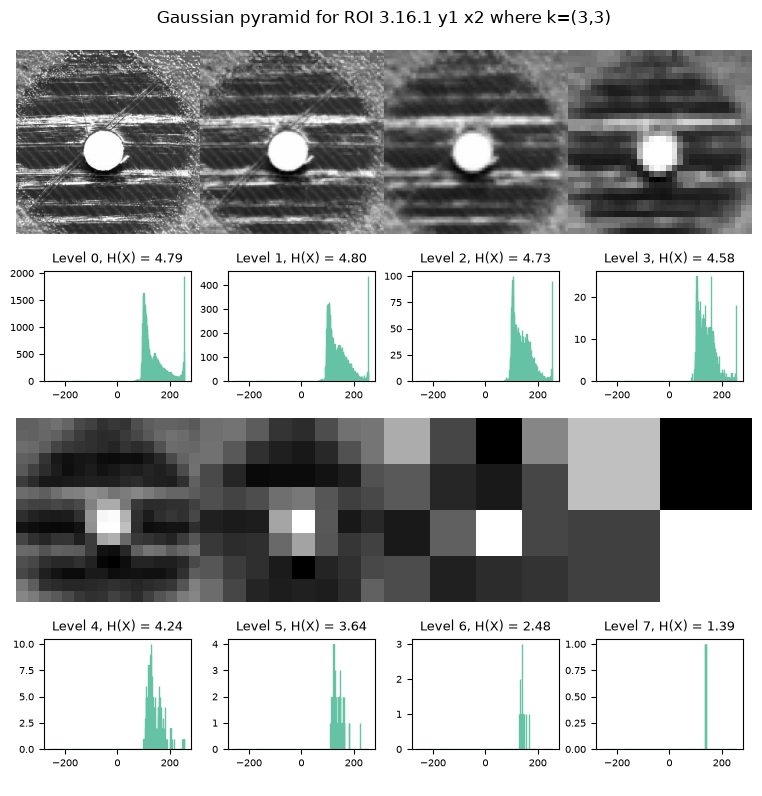

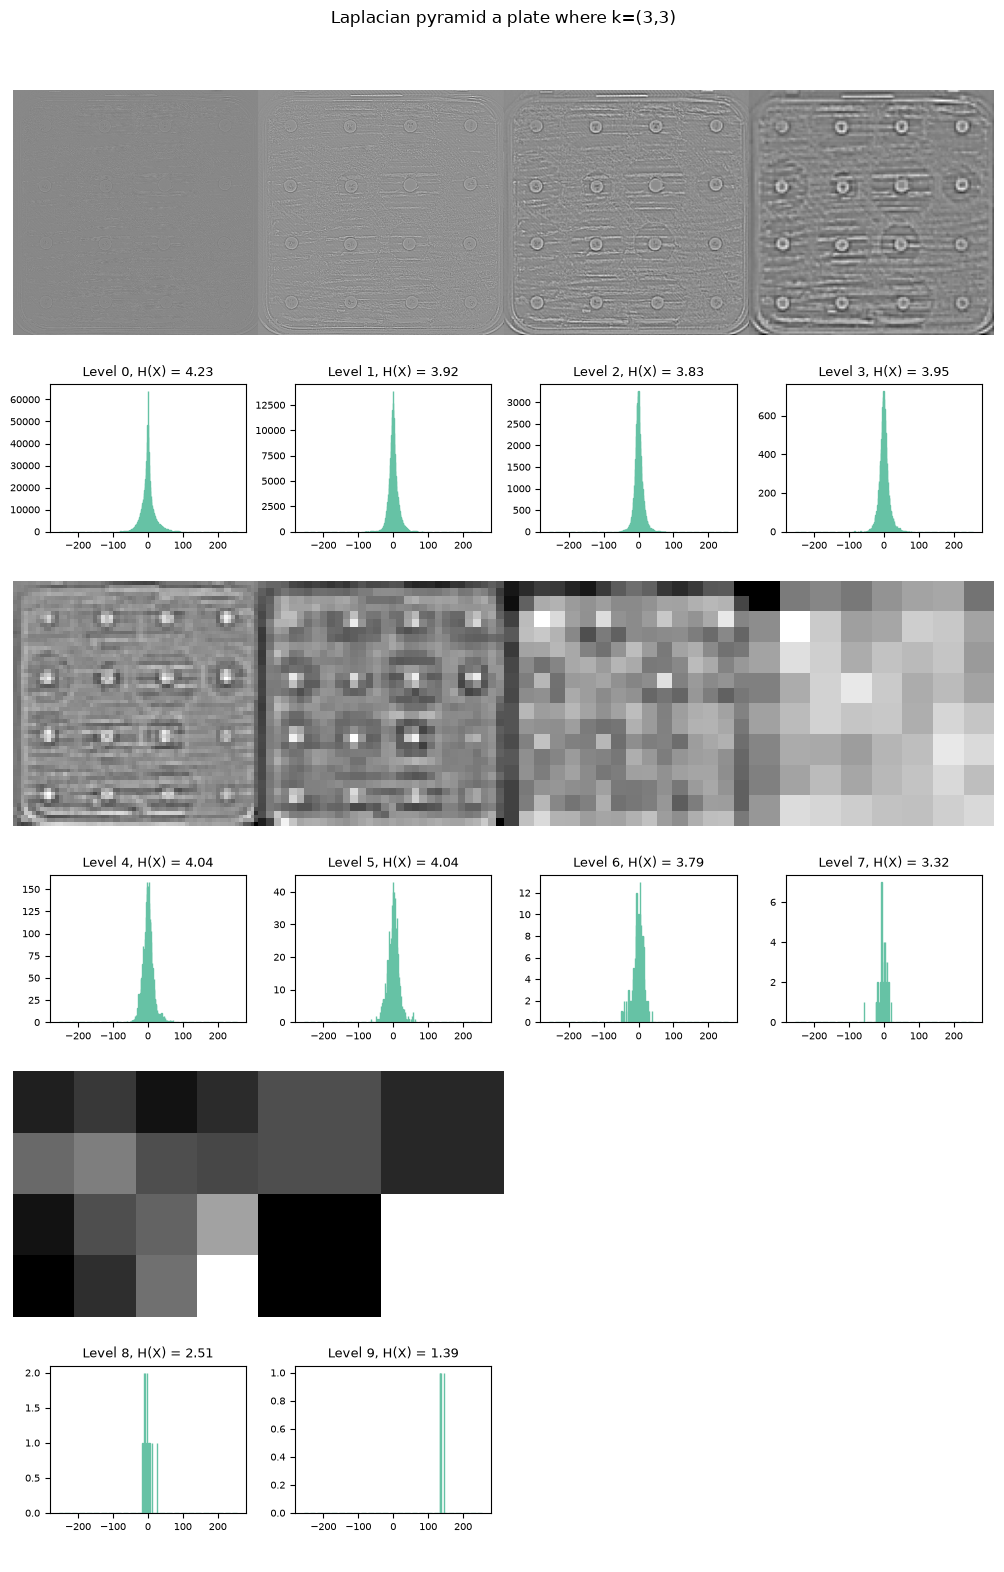

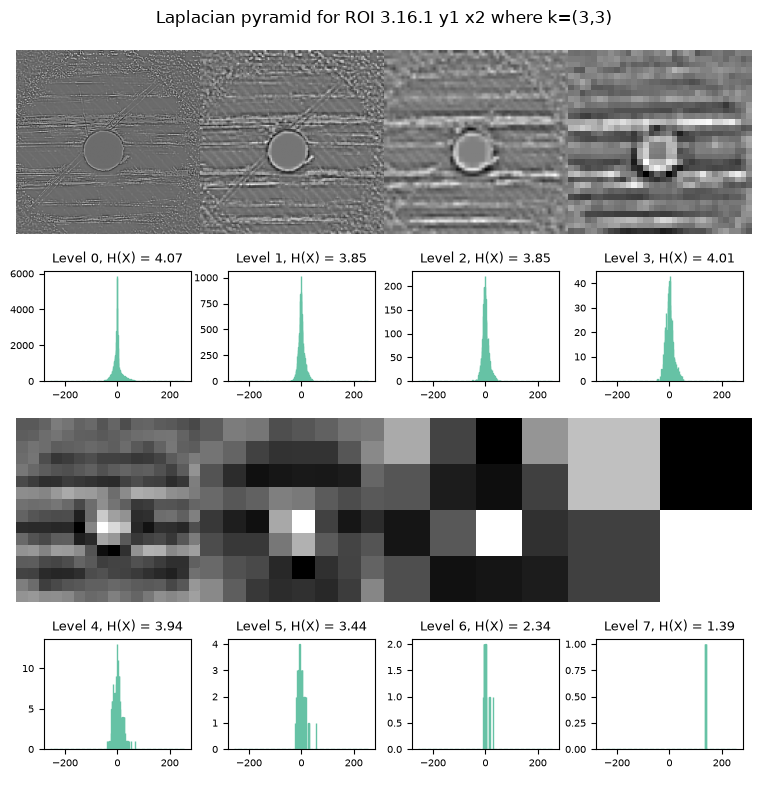

In [31]:
show_pyramid(o3161_gp, "Gaussian pyramid for a plate where k=(3,3) and N=10", 20, 16, True)

show_pyramid(d3161y1x2_gp, "Gaussian pyramid for ROI 3.16.1 y1 x2 where k=(3,3)", 16, 8, True)

show_pyramid(o3161_lp, "Laplacian pyramid a plate where k=(3,3)", 20, 16, True)

show_pyramid(d3161y1x2_lp, "Laplacian pyramid for ROI 3.16.1 y1 x2 where k=(3,3)", 16, 8, True)

A larger range (-255, 256) was selected to compare the Gaussian and Laplace pyramids (bins=511). We can see the Gaussian histograms positive values whereas the Laplacian histograms are centered around zero. Looking at the first level, we can see the histograms are similar with the number of pixels in each bin and the number of filled bins decreasing. The same can be seen for Laplacian with the exception of centering around zero. The Shannon Entropy H(X) values are around 5 for levels 0 through 3 before shifting to 4 then finally 3 at 7, 2 at 8, and 1 at level 9, which means the amount of information retained is good for halving the image. Looking the same image for the Laplace, we see the Shannon Entropy is lower, starting around 4. This is expected because more information is lost due to downsampling and Gaussian blur then expanding (upsampling). Information lost with upsampling is unrecoverable.

## Blending Images

In [32]:
def blend(image_a, image_b, threshold, N):
    threshold = threshold / 255
    ga = gaussian_pyramid(image_a, N=N)
    gb = gaussian_pyramid(image_b, N=N)
    gt = gaussian_pyramid(threshold, N=N)

    la = laplacian_pyramid(ga)
    lb = laplacian_pyramid(gb)

    Ls = []
    
    for lan, lbn, gtn in zip(la, lb, gt):
        Ls.append(lan*gtn + lbn*(1-gtn))

    rLs = Ls[::-1]
    ln = rLs[0]
    for ln_next in rLs[1:]:
        ln = ln_next + expand(ln)
    return ln

## Loading images

We'll load images to use for blending and to make a threshold. The the ROI on the left has glare from the reflection distorting the zone of inhibition. We'll use a threshold to artificially remove the glare through blending.

In [41]:
roi_df

,roi,label,antibiotic,diameter,y,x
0,4_37_1__denoised-y0-x0,resistant,am10,6,0,0
1,4_37_1__denoised-y0-x1,susceptible,fep,27,0,256
2,4_37_1__denoised-y0-x2,resistant,fox,14,0,512
3,4_37_1__denoised-y0-x3,susceptible,mem,28,0,768
4,4_37_1__denoised-y1-x0,resistant,cpd,10,256,0
...,...,...,...,...,...,...
3595,6_70_1__denoised-y2-x3,0,NaN,NaN,512,768
3596,6_70_1__denoised-y3-x0,0,NaN,NaN,768,0
3597,6_70_1__denoised-y3-x1,0,NaN,NaN,768,256
3598,6_70_1__denoised-y3-x2,0,NaN,NaN,768,512


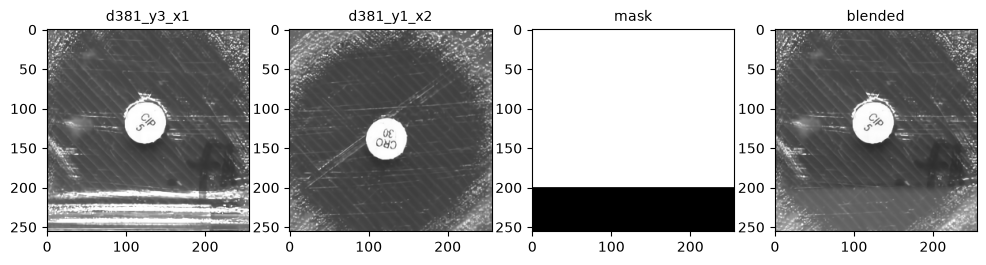

In [42]:
d381_y3_x1_row = roi_df["roi"] == "3_8_1__denoised-y3-x1"
idx = roi_df.index[d381_y3_x1_row][0]
d381_y3_x1 = get_roi(roi_df.iloc[idx], processed, 1024//4, 1024//4)

d381_y1_x2_row = roi_df["roi"] == "3_8_1__denoised-y1-x2"
idx = roi_df.index[d381_y1_x2_row][0]
d381_y1_x2 = get_roi(roi_df.iloc[idx], processed, 1024//4, 1024//4)

mask = np.zeros_like(d381_y3_x1)
height, width = mask.shape[:2]
mask[0:200, 0:width] = 255

blended = blend(d381_y3_x1, d381_y1_x2, mask, 9)

fig, axes = plt.subplots(1, 4, figsize=(12, 9))
for ax, img, name in zip(axes, [d381_y3_x1, d381_y1_x2, mask, blended], ["d381_y3_x1", "d381_y1_x2", "mask", "blended"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    #ax.axis("off")
    ax.set_title(name, fontsize=10)

In [43]:
def glcm(image, directions=[0, 45, 90, 135], d=1):
    """Reduces to 16"""

    if len(directions) == 0 or not set(directions).issubset(set([0, 45, 90, 135])):
        raise ValueError("Invalid direction. Must be at least one of [0, 45, 90, 135]")
    # Convert to grayscale if color
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = image // 16
    glcms = {direction: np.zeros([16, 16]) for direction in directions}
    height, width = image.shape[:2]
    if d <= 0 or d >= height or d >= width:
        raise ValueError(f"d must be greater than 0 but less than {height} or {width}")
    for i in range(height):
        for j in range(width):
            if 0 in directions and j+d < width:
                glcms[0][image[i,j], image[i,j+d]] += 1
            if 45 in directions and 0 <= i-d and j+d < width:
                glcms[45][image[i,j], image[i-d,j+d]] += 1
            if 90 in directions and 0 <= i-d:
                glcms[90][image[i,j], image[i-d,j]] += 1
            if 135 in directions and 0 <= i-d and 0 <= j-d:
                glcms[135][image[i,j], image[i-d,j-d]] += 1
    normalized_tables = {}
    for direction in directions:
        symmetric_glcm = glcms[direction] + glcms[direction].T
        normalized_tables[direction] = symmetric_glcm / symmetric_glcm.sum()
    return normalized_tables

def haralick_features(image, k=2, n=1, directions=[0, 45, 90, 135], d=1):
    nt = glcm(image, directions=directions, d=d)

    features = {}
    stack = np.stack(list(nt.values()))
    levels = np.indices((16,16))
    # (avg) energy: p ** 2
    features["haralick_energy"] = np.square(stack).sum() /  len(nt)
    # (avg) entropy: p * log p
    nonzero_stack = stack[stack > 0]
    features["haralick_entropy"] = (-nonzero_stack * np.log(nonzero_stack)).sum() / len(nt)
    # (avg) contrast: (i-j) ** k * p ** n where i and j are the levels
    features["haralick_contrast"] = (((levels[0] - levels[1]) ** k) * (stack ** n)).sum() / len(nt)
    # (a single value out of all values in all directions) max probability: max(p)
    features["haralick_max"] = np.max(stack)
    # homogeneity: p / (1+|i-j|)
    features["haralick_homogeneity"] = (stack / (1+np.absolute(levels[0]-levels[1]))).sum() / len(nt)
    return features

In [44]:
from skimage.filters import threshold_multiotsu

def get_binary_image(image):
    thresholds = threshold_multiotsu(image, classes=3)
    binary_image = np.zeros_like(image)
    binary_image[(image < thresholds[0]) | (image >= thresholds[1])] = 255
    return binary_image

def N(image, s):
    height, width = image.shape[:2]
    hs, ws = height // s, width // s
    n_s = 0
    for h in range(hs):
        for w in range(ws):
            n_s += np.any(image[h*s:h*s+s, w*s:w*s+s] == 255)
    return n_s

# box counting
def box_count(image):
    """image: binary image"""

    image = get_binary_image(image)
    height, width = image.shape[:2]
    gcd = math.gcd(height, width)

    d = []
    n = {}
    ss = [s for s in range(2, gcd) if height % s == 0 and width % s == 0 and s > 1 and s < height and s < width]
    if len(ss) < 2:
        return np.nan
    
    for s in ss:
        n[s] = N(image, s)

    s = ss[0]
    ns = n[s]
    for s1 in ss[1:]:
        if ns == 0 or n[s] == 0:
            continue
        # recommended by claude sonnet 5.5 to switch order of denominator to make positive
        d.append((math.log(ns) - math.log(n[s1])) / (math.log(s1) - math.log(s)))
        s = s1
        ns = n[s1]

    return np.mean(d) if len(d) > 0 else np.nan

def box_count_features(image):
    return {"box_count": box_count(image)}

In [45]:
def get_chain_code(image):
    """image must be binary"""
    image = get_binary_image(image)
    contours, hierarchy = cv2.findContours(image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    canvas = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    return contours, cv2.drawContours(canvas, contours, -1, (0,255,0), 1)

def bin_directions(points):
    values = np.zeros(8)
    point = points[:1]
    for next_point in np.concatenate((points[1:], point)):
        if np.all((next_point - point) == np.array([[-1, 0]])):
            values[0] += 1
        elif np.all((next_point - point) == np.array([[-1, 1]])):
            values[1] += 1
        elif np.all((next_point - point) == np.array([[0, 1]])):
            values[2] += 1
        elif np.all((next_point - point) == np.array([[1, 1]])):
            values[3] += 1
        elif np.all((next_point - point) == np.array([[1, 0]])):
            values[4] += 1
        elif np.all((next_point - point) == np.array([[1, -1]])):
            values[5] += 1
        elif np.all((next_point - point) == np.array([[0, -1]])):
            values[6] += 1
        elif np.all((next_point - point) == np.array([[-1, -1]])):
            values[7] += 1
        else:
            raise ValueError(f"Difference greater than 1: {point} - {next_point}")
        point = next_point
    return values

def chain_code_features(image):
    contours, hierarchy = cv2.findContours(image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    values = np.zeros(8)
    for points in contours:
        if len(points) < 2:
            continue
        v = bin_directions(points)
        values = values + v
    values = np.zeros(8) if sum(values) == 0 else values / sum(values)
    return {f"chain_code_{i}": v for i, v in enumerate(values)}

In [46]:
def get_areas(image):
    """image must be binary"""

    image = get_binary_image(image)
    contours, _ = cv2.findContours(image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) == 0:
        return 0, 0, 0

    num_of_contours = len(contours)
    net_area = np.count_nonzero(image == 255)
    convex_areas = np.zeros(num_of_contours)
    perimeters = np.zeros(num_of_contours)

    for i in range(len(contours)):
        hull = cv2.convexHull(contours[i])
        convex_areas[i] = cv2.contourArea(hull)
        perimeters[i] = cv2.arcLength(hull, closed=True)

    return net_area, np.mean(convex_areas), np.mean(perimeters)

def areas_features(image):
    net_area, convex_area, perimeter = get_areas(image)
    return {"net_area": net_area, "convex_area": convex_area, "perimeter": perimeter}

In [47]:
def lbp(image):
    # we'll do a simple version where p = 8 neighbors
    r = 1
    # Convert to grayscale if color
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    height, width = image.shape[:2]
    codes = np.zeros([height-2, width-2])
    for i in range(1, height-1):
        for j in range(1, width-1):
            # we should reorder for the weights
            neighbors = image[i-r:i+r+1,j-r:j+r+1].ravel()
            neighbors = neighbors[[5, 2, 1, 0, 3, 6, 7, 8]]
            # find only neighbors greater than or equal to the center pixel
            binary = neighbors >= image[i,j]
            # sum the weights that based on the order
            codes[i-1,j-1] = sum((2 ** np.arange(8)) * binary)
    return codes.astype(int)

def lbp_features(image):
    codes = lbp(image)
    counts, _ = np.histogram(codes, bins=256, range=(0,256))
    hist = counts / codes.size
    return {f"lbp_{i}": val for i, val in enumerate(hist)}

## Class counts

In [64]:
def count_class(df, label="label"):
    counts = df[[label]].value_counts()
    percent = df[[label]].value_counts(normalize=True) * 100
    return pd.DataFrame({"count": counts, "percent": percent.round(1)})

roi_df = roi_df.dropna()
count_class(roi_df)


,count,percent
label,,
susceptible,100,52.1
resistant,84,43.8
not read,5,2.6
intermediate,3,1.6


In [83]:
# We drop not read and intermediate since there are only a few
roi_df = roi_df[roi_df["label"].isin(["susceptible", "resistant"])]

#Load images into roi_df

roi_df["image"] = None
for row in roi_df.itertuples():
    roi_df.at[row.Index, "image"] = get_roi(row, processed)
roi_df

,roi,label,antibiotic,diameter,y,x,image
0,4_37_1__denoised-y0-x0,resistant,am10,6,0,0,"[[17, 17, 17, 18, 18, 18, 18, 18, 18, 19, 19, ..."
1,4_37_1__denoised-y0-x1,susceptible,fep,27,0,256,"[[48, 46, 42, 35, 26, 18, 14, 14, 18, 26, 33, ..."
2,4_37_1__denoised-y0-x2,resistant,fox,14,0,512,"[[11, 16, 26, 29, 25, 21, 18, 17, 16, 16, 14, ..."
3,4_37_1__denoised-y0-x3,susceptible,mem,28,0,768,"[[25, 25, 25, 25, 25, 23, 19, 13, 10, 9, 10, 1..."
4,4_37_1__denoised-y1-x0,resistant,cpd,10,256,0,"[[55, 53, 51, 50, 51, 55, 59, 63, 67, 71, 74, ..."
...,...,...,...,...,...,...,...
2315,5_16_1__denoised-y2-x3,resistant,CN,6,512,768,"[[150, 157, 159, 157, 151, 146, 148, 149, 143,..."
2316,5_16_1__denoised-y3-x0,susceptible,ETP,31,768,0,"[[0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 3, 4, 6, 11, 2..."
2317,5_16_1__denoised-y3-x1,resistant,CIP,6,768,256,"[[147, 141, 137, 133, 133, 136, 139, 141, 144,..."
2318,5_16_1__denoised-y3-x2,resistant,PEF,6,768,512,"[[134, 137, 139, 142, 177, 237, 255, 238, 193,..."


## With Haralick, box counting, chain code, areas, LBP

In [94]:
FUNCS = [haralick_features, box_count_features, chain_code_features, 
         areas_features, lbp_features]

def extract_features(image, funcs):
    features = {}
    for func in funcs:
        features = features | func(image)
    return features

def prepare_features_for_images(df, funcs=FUNCS, pyramid=None, verbose=True):
    """Expects columns: label, roi, image; can take a pyramid function; returns train_X, labels"""
    all_features = []
    labels = []
    for row in df.itertuples():
        if verbose:
            print(f"Processing {row.roi} with label {row.label}")
        if pyramid is not None:
            features = {}

            pyr = pyramid(row.image)
            for i, level in enumerate(pyr):
                roi_features = extract_features(level, funcs)
                features |= {f"{key}_L{i}": value for key, value in roi_features.items()}
        else:
            features = extract_features(row.image, funcs)
        all_features.append(features)
        labels.append(row.label)
    return pd.DataFrame(all_features), np.array(labels)

# The following code is based on https://gogulilango.com/software/texture-recognition
def train_features(train_X, labels, random_state=5, max_iter=1000, verbose=True):
    """Takes train_X, labels from prepare_features_for_images"""
    if verbose:
        print(f"Features: {train_X.shape}, Labels: {len(labels)}")
    svm = make_pipeline(StandardScaler(),
                        LinearSVC(random_state=random_state,
                                  max_iter=max_iter))
    if verbose:
        print("Fitting data and labels to model")
    svm.fit(train_X, labels)
    return svm

# Suggested by Claude Sonnet 5.5
def roi_group(df):
    """Uses roi column to split into groups"""
    return df["roi"].str.rsplit("-y", n=1).str[0].to_numpy()

groups = roi_group(roi_df)
train_X, y = prepare_features_for_images(roi_df, verbose=False)
svm = train_features(train_X, y, verbose=False)
cv = GroupKFold(n_splits=4)
all_features_pred = cross_val_predict(svm, train_X, y, cv=cv, groups=groups)
print(classification_report(y, all_features_pred, zero_division=0))
print(confusion_matrix(y, all_features_pred, labels=["resistant", "susceptible"]))

              precision    recall  f1-score   support

   resistant       0.83      0.71      0.77        84
 susceptible       0.79      0.88      0.83       100

    accuracy                           0.80       184
   macro avg       0.81      0.80      0.80       184
weighted avg       0.81      0.80      0.80       184

[[60 24]
 [12 88]]


## Haralick and LBP (no pyramid)

In [87]:
funcs = [haralick_features, lbp_features]
train_X, y = prepare_features_for_images(roi_df, funcs=funcs, verbose=False)
svm = train_features(train_X, y, verbose=False)
cv = GroupKFold(n_splits=4)
without_pyramid_pred = cross_val_predict(svm, train_X, y, cv=cv, groups=groups)
print(classification_report(y, without_pyramid_pred, zero_division=0))
print(confusion_matrix(y, without_pyramid_pred, labels=["resistant", "susceptible"]))

              precision    recall  f1-score   support

   resistant       0.83      0.68      0.75        84
 susceptible       0.77      0.88      0.82       100

    accuracy                           0.79       184
   macro avg       0.80      0.78      0.78       184
weighted avg       0.79      0.79      0.79       184

[[57 27]
 [12 88]]


## Haralick and LBP with Gaussian pyramid

In [91]:
funcs = [haralick_features, lbp_features]
train_X, y = prepare_features_for_images(roi_df, funcs=funcs, pyramid=gaussian_pyramid, verbose=False)
svm = train_features(train_X, y, verbose=False)
cv = GroupKFold(n_splits=4)
with_gaussian_pyramid_pred = cross_val_predict(svm, train_X, y, cv=cv, groups=groups)
print(classification_report(y, with_gaussian_pyramid_pred, zero_division=0))
print(confusion_matrix(y, with_gaussian_pyramid_pred, labels=["resistant", "susceptible"]))

              precision    recall  f1-score   support

   resistant       0.85      0.88      0.87        84
 susceptible       0.90      0.87      0.88       100

    accuracy                           0.88       184
   macro avg       0.87      0.88      0.87       184
weighted avg       0.88      0.88      0.88       184

[[74 10]
 [13 87]]


## Haralick and LBP with Laplacian pyramid

In [99]:
# Modified laplacian so we can use it with features
def laplacian_pyramid2(image, ksize=(3,3)):
    Ls = []
    gpyramid = gaussian_pyramid(image)
    for n in range(len(gpyramid[:-1])):
        Ls.append(gpyramid[n].astype(float) - expand(gpyramid[n+1]).astype(float))
    Ls.append(gpyramid[-1].astype(float))
    return Ls

# Suggested by Claude Sonnet 5.5
def rescale_to_uint8(level):
    low, high = level.min(), level.max()
    if high == low:
        return np.zeros(level.shape, dtype=np.uint8)
    return ((level - low) / (high - low) * 255).round().astype(np.uint8)

# Suggested by Claude Sonnet 5.5
def laplacian_pyramid_uint8(image, **kwargs):
    return [rescale_to_uint8(level) for level in laplacian_pyramid2(image, **kwargs)]

funcs = [haralick_features, lbp_features]
train_X, y = prepare_features_for_images(roi_df, funcs=funcs, pyramid=laplacian_pyramid_uint8, verbose=False)
svm = train_features(train_X, y, verbose=False)
cv = GroupKFold(n_splits=4)
with_laplacian_pyramid_pred = cross_val_predict(svm, train_X, y, cv=cv, groups=groups)
print(classification_report(y, with_laplacian_pyramid_pred, zero_division=0))
print(confusion_matrix(y, with_laplacian_pyramid_pred, labels=["resistant", "susceptible"]))

              precision    recall  f1-score   support

   resistant       0.87      0.92      0.89        84
 susceptible       0.93      0.88      0.90       100

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184

[[77  7]
 [12 88]]
